# 02 · Will it go on sale in the next 14 days? (Classification)

Notebook 01 used survival analysis. Here we ask the buyer's question directly as **binary classification**, using the CPSC 330 toolkit:

- **Lecture 2:** baselines first (`DummyClassifier`)
- **Lectures 5–6:** `make_pipeline` + `make_column_transformer`
- **Lecture 9:** classification metrics. Sales are the minority class, so accuracy alone misleads; we use **average precision** and **ROC AUC**.
- **Lecture 11:** gradient boosting (**LightGBM**)
- **Lecture 12:** **SHAP** to explain predictions
- **Lecture 19:** time-based split, never shuffled

**How the rows are built.** For every gap between sales, we "check in" at several points: on the day the last sale ended, 7 days later, 14, 30, 60 and 90 days later, as long as the game is still waiting. Each check-in becomes a row:

> *Standing on this day, does a sale start within the next 14 days?*

**Fixing the imbalance between games.** Some games have 60+ sales, so they'd dominate the training data. Every game gets **equal total weight** (`sample_weight = 1 / rows for that game`). Notebook 01 left this as a caveat; here it's fixed.

In [1]:
from pathlib import Path

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lifelines import CoxPHFitter
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 30)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = duckdb.connect(str(ROOT / "data" / "warehouse.duckdb"), read_only=True)

HORIZON = 14                              # "sale within the next 14 days?"
CHECK_DAYS = [0, 7, 14, 30, 60, 90]       # when we check in during each gap
CUTOFF = pd.Timestamp("2025-01-01")       # same cutoff as notebook 01

/home/aryasardesai/venvs/steamwait/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load gaps and the sale calendar

In [2]:
gaps = con.sql("""
    select g.*, d.name,
           date_diff('day', d.release_date, g.gap_start) / 365.25 as game_age_years
    from fct_sale_gaps g
    join dim_games d using (appid)
    where d.is_modelable
""").df()
gaps["gap_start"] = pd.to_datetime(gaps["gap_start"])
gaps["regular_dollars"] = gaps["regular_cents"] / 100

# big Steam sales: found in the data (past) + announced in the seed (future)
event_dates = np.sort(pd.to_datetime(con.sql("""
    select start_date from fct_platform_sale_days where is_major_event
    union select start_date from steam_events where event_type = 'seasonal'
""").df()["start_date"]).values)
print(f"{len(gaps):,} gaps, {gaps['appid'].nunique():,} games, {len(event_dates)} major sale events")

91,998 gaps, 2,252 games, 59 major sale events


## 2. Build check-in rows

A row exists only while the game is **still waiting** (`check_day < duration`). The label must be fully known: if the gap was censored before the 14-day window ended, we don't know the answer, so the row is dropped.

In [3]:
rows = []
for t in CHECK_DAYS:
    g = gaps[gaps["duration_days"] > t].copy()
    g["days_waited"] = t
    g["check_date"] = g["gap_start"] + pd.to_timedelta(t, unit="D")
    days_left = g["duration_days"] - t
    g["sale_within_14d"] = g["event_observed"] & (days_left <= HORIZON)
    known = g["event_observed"] | (days_left > HORIZON)   # censored inside the window = unknown
    rows.append(g[known])
df = pd.concat(rows, ignore_index=True)

# calendar features AS OF the check date (not the gap start)
idx = np.searchsorted(event_dates, df["check_date"].values, side="right")
next_evt = pd.to_datetime(np.where(idx < len(event_dates), event_dates[np.minimum(idx, len(event_dates) - 1)], np.datetime64("NaT")))
df["days_to_next_major_event"] = (next_evt - df["check_date"]).dt.days
prev_idx = np.searchsorted(event_dates, df["check_date"].values, side="right") - 1
prev_evt = pd.to_datetime(np.where(prev_idx >= 0, event_dates[np.maximum(prev_idx, 0)], np.datetime64("NaT")))
df["days_since_major_event"] = (df["check_date"] - prev_evt).dt.days
df["check_month"] = df["check_date"].dt.month

print(f"{len(df):,} check-in rows")
print(f"positive rate (sale within {HORIZON} days): {df['sale_within_14d'].mean():.1%}")

331,360 check-in rows
positive rate (sale within 14 days): 25.7%


/tmp/ipykernel_7113/420553332.py:14: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  next_evt = pd.to_datetime(np.where(idx < len(event_dates), event_dates[np.minimum(idx, len(event_dates) - 1)], np.datetime64("NaT")))
/tmp/ipykernel_7113/420553332.py:17: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  prev_evt = pd.to_datetime(np.where(prev_idx >= 0, event_dates[np.maximum(prev_idx, 0)], np.datetime64("NaT")))


## 3. Time-based split and per-game weights

Same idea as notebook 01: train on check-ins **before** the cutoff, test on check-ins after it. A training row whose 14-day window crosses the cutoff would use future information for its label, so it's dropped.

In [4]:
window_end = df["check_date"] + pd.Timedelta(days=HORIZON)
train = df[window_end < CUTOFF].copy()
test = df[df["check_date"] >= CUTOFF].copy()

for part in (train, test):
    part["weight"] = 1.0 / part.groupby("appid")["appid"].transform("size")

numeric_feats = [
    "days_waited", "days_to_next_major_event", "days_since_major_event",
    "regular_dollars", "prev_sale_cut", "prev_sale_length_days", "prev_gap_days",
    "game_age_years", "after_sale_number",
]
categorical_feats = ["check_month"]
target = "sale_within_14d"

X_train, y_train, w_train = train[numeric_feats + categorical_feats], train[target], train["weight"]
X_test, y_test, w_test = test[numeric_feats + categorical_feats], test[target], test["weight"]
print(f"train {len(train):,} rows ({y_train.mean():.1%} positive) | test {len(test):,} rows ({y_test.mean():.1%} positive)")

train 259,467 rows (25.2% positive) | test 70,756 rows (26.6% positive)


/tmp/ipykernel_7113/1221005042.py:1: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  window_end = df["check_date"] + pd.Timedelta(days=HORIZON)


## 4. Models: baselines first

Metrics (Lecture 9): sales are the minority class, so we report
- **Average precision (AP):** area under the precision-recall curve. A random model scores about the positive rate.
- **ROC AUC:** 0.5 = random, 1.0 = perfect.

Both are computed **per-game weighted**, so a game with 60 sales doesn't count 60 times.

In [5]:
def evaluate(name, p_train, p_test):
    results[name] = {
        "train AP": average_precision_score(y_train, p_train, sample_weight=w_train),
        "test AP": average_precision_score(y_test, p_test, sample_weight=w_test),
        "train ROC AUC": roc_auc_score(y_train, p_train, sample_weight=w_train),
        "test ROC AUC": roc_auc_score(y_test, p_test, sample_weight=w_test),
    }

results = {}

dummy = DummyClassifier(strategy="prior").fit(X_train, y_train, sample_weight=w_train)
evaluate("Dummy", dummy.predict_proba(X_train)[:, 1], dummy.predict_proba(X_test)[:, 1])

# rule of thumb: "a big Steam sale starts within 14 days"
seasonal = lambda X: (X["days_to_next_major_event"] <= HORIZON).astype(float)
evaluate("Seasonal rule", seasonal(X_train), seasonal(X_test))
pd.DataFrame(results).T.round(3)

,train AP,test AP,train ROC AUC,test ROC AUC
Dummy,0.206,0.230,0.500,0.500
Seasonal rule,0.521,0.522,0.787,0.726


### Logistic regression (Lecture 7) with a `ColumnTransformer` (Lectures 5–6)

In [6]:
preprocessor = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), numeric_feats),
    (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")),
     categorical_feats),
)
lr = make_pipeline(preprocessor, LogisticRegression(max_iter=2000))
lr.fit(X_train, y_train, logisticregression__sample_weight=w_train)
evaluate("Logistic regression", lr.predict_proba(X_train)[:, 1], lr.predict_proba(X_test)[:, 1])

### LightGBM (Lecture 11)

Trees don't need scaling, and LightGBM handles missing values itself, so there's no preprocessing. `check_month` is passed as a categorical feature.

In [7]:
lgbm = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                          min_child_samples=50, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, random_state=330, verbose=-1)
lgbm.fit(X_train.astype({"check_month": "category"}), y_train, sample_weight=w_train)
p_lgbm_test = lgbm.predict_proba(X_test.astype({"check_month": "category"}))[:, 1]
evaluate("LightGBM", lgbm.predict_proba(X_train.astype({"check_month": "category"}))[:, 1], p_lgbm_test)

### Head to head with the Cox model from notebook 01

Cox can answer the same question: P(sale within 14 days | already waited t days) = 1 − S(t+14)/S(t). We refit it on the training gaps (censored at the cutoff, as in notebook 01) and score the **same test rows**.

**This comparison isn't quite even, and that's the point.** Cox's features are fixed at the start of the gap, so it can't use "days to the next big sale" *as of the check-in day*. That would be a time-varying covariate, which the survival lecture lists as a more advanced topic. The classifiers get it for free, because each check-in row has its own calendar features. If they win by a lot, this is a big part of why.

In [8]:
cox_feats = ["regular_dollars", "prev_sale_cut", "prev_sale_length_days", "prev_gap_days",
             "game_age_years", "after_sale_number"]
g_train = gaps[gaps["gap_start"] < CUTOFF].copy()
d2c = (CUTOFF - g_train["gap_start"]).dt.days
late = g_train["duration_days"] > d2c
g_train.loc[late, "event_observed"] = False
g_train.loc[late, "duration_days"] = d2c[late]

cox_pre = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(g_train[cox_feats])
cox_df = pd.DataFrame(cox_pre.transform(g_train[cox_feats]), columns=cox_feats)
cox_df["duration"] = g_train["duration_days"].clip(lower=0.5).to_numpy()
cox_df["event"] = g_train["event_observed"].astype(int).to_numpy()
cph = CoxPHFitter(penalizer=0.1).fit(cox_df, "duration", "event")

def cox_prob(part):
    X = pd.DataFrame(cox_pre.transform(part[cox_feats]), columns=cox_feats)
    t = part["days_waited"].to_numpy()
    out = np.empty(len(part))
    for d in np.unique(t):
        m = t == d
        s = cph.predict_survival_function(X[m], times=[d, d + HORIZON])
        out[m] = (1 - s.iloc[1] / s.iloc[0].clip(lower=1e-9)).to_numpy()
    return out

evaluate("Cox PH (notebook 01)", cox_prob(train), cox_prob(test))
pd.DataFrame(results).T.round(3)

,train AP,test AP,train ROC AUC,test ROC AUC
Dummy,0.206,0.230,0.500,0.500
Seasonal rule,0.521,0.522,0.787,0.726
Logistic regression,0.570,0.529,0.808,0.746
LightGBM,0.860,0.803,0.945,0.920
Cox PH (notebook 01),0.336,0.349,0.675,0.653


## 5. Why does LightGBM say what it says? SHAP (Lecture 12)

Each dot is one test row. Features are ordered by overall impact. Red means a high feature value; to the right means "more likely to go on sale within 14 days".

/home/aryasardesai/venvs/steamwait/lib/python3.14/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


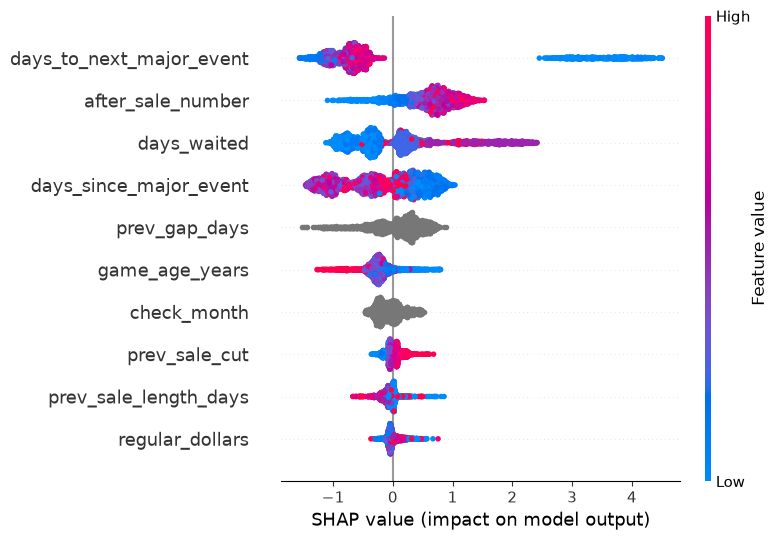

In [9]:
sample = X_test.sample(min(3000, len(X_test)), random_state=330).astype({"check_month": "category"})
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(sample)
shap.summary_plot(shap_values, sample, show=False)
plt.tight_layout()

## 6. What it looks like for a buyer

Five games from the test set, with the model's probability of a sale in the next 14 days and what actually happened.

In [10]:
show = test.assign(p=p_lgbm_test).sample(5, random_state=7)
show[["name", "check_date", "days_waited", "days_to_next_major_event", "regular_dollars", "p", "sale_within_14d"]] \
    .rename(columns={"p": "P(sale in 14 days)", "sale_within_14d": "actually went on sale"}).round(2)

,name,check_date,days_waited,days_to_next_major_event,regular_dollars,P(sale in 14 days),actually went on sale
237155,Tinboy,2025-04-21,14,66,5.69,0.05,False
159769,Typer Shark! Deluxe,2025-05-22,7,35,4.99,0.00,False
105088,Mon Amour,2026-04-02,7,84,10.99,0.11,False
184498,"Sir, You Are Being Hunted",2025-01-16,14,56,21.99,0.53,False
2860,RRRR3,2026-07-09,0,84,1.19,0.26,True


## 7. Takeaways (fill in from your run)

- **Best model on 2025–26 data:** _which one, and by how much over the seasonal rule?_
- **LightGBM vs Cox:** _does the tree model beat Cox? Trees can learn "sales cluster right before big events" without the proportional-hazards assumption._
- **Top SHAP features:** _is it still the calendar first, then the game's own habit?_
- **Per-game weighting:** every game counts equally, so the scores describe a *typical* game, not the constant discounters.

**Next:** tune LightGBM with `TimeSeriesSplit` (Lectures 8 and 19), check calibration (does "70%" really mean 70%?), then freeze predictions before the **Winter Sale on Dec 17** and score them afterwards.